# BoneForge3D: 3D Bone Mesh Reconstruction from CT Segmentation Masks

## Abstract
In medical image computing, volumetric segmentation models output discrete voxel masks. While voxel arrays define anatomical regions, surgical CAD environments, finite element modeling, and 3D printing pipelines require continuous, watertight boundary representations (STL meshes).

BoneForge3D implements an end-to-end Python reconstruction pipeline that converts multi-class vertebral CT segmentation masks into production-ready, watertight 3D triangle meshes. The pipeline accounts for physical voxel anisotropy, performs isosurface extraction via Marching Cubes, applies Laplacian smoothing to suppress discretization artifacts, repairs non-manifold geometry, calculates morphometric properties (volume, surface area, compactness), and validates reconstructed meshes in 3D Slicer.


## Geometric and Medical Imaging Terminology

* **Voxel (Volume Element):** The discrete 3D unit of a medical scan array. A scan of dimension (512, 512, 542) contains approximately 142 million voxels.
* **Physical Spacing (Zooms):** The real-world millimeter distance between adjacent voxel centers along the (X, Y, Z) axes. CT acquisitions are typically anisotropic (e.g., 0.68 mm in-plane resolution with 0.90 mm slice thickness).
* **NIfTI Format (.nii.gz):** Standard compressed neuroimaging and spinal research format storing voxel intensity data alongside affine coordinate matrices.
* **Marching Cubes (Lorensen & Cline, 1987):** An isosurface extraction algorithm that evaluates 2x2x2 voxel neighborhoods across 256 topological configurations (reduced to 15 canonical cases by symmetry) to place intersecting triangles at an isovalue boundary.
* **Polygon Mesh:** A boundary representation consisting of 3D vertices, connecting triangular faces, and surface normal vectors.
* **Watertight Manifold (2-Manifold):** A closed surface mesh where every edge is shared by exactly two triangular faces, forming an unambiguous internal volume with no boundary openings or self-intersections.
* **Laplacian Smoothing:** A mesh relaxation algorithm that moves each vertex toward the barycenter of its topological neighbors, attenuating high-frequency voxel staircase artifacts while preserving volume.
* **STL Format (Stereolithography):** Industry-standard format storing unindexed triangular facet normals and vertices, universally supported in surgical navigation, CAD, and 3D printing software.
* **Compactness (Sphericity):** A dimensionless morphometric metric comparing surface area to volume:
  $$\text{Compactness} = \frac{(36 \pi V^2)^{1/3}}{A}$$
  A sphere has a compactness of 1.0, while complex structures like vertebrae have characteristic values between 0.45 and 0.55.


## 1. Environment Configuration and Dependencies

The reconstruction pipeline uses the following libraries:
* `nibabel`: NIfTI I/O and affine spatial geometry parsing
* `scikit-image`: Marching Cubes isosurface extraction
* `trimesh`: Topological validation, Laplacian smoothing, and STL export
* `pandas` and `numpy`: Numerical processing and tabular metrics
* `matplotlib`: Orthogonal cross-sections and 3D projection renders
* `huggingface_hub`: Programmatic dataset acquisition


In [1]:
# Install dependencies
!pip install nibabel scikit-image trimesh open3d pyvista huggingface_hub pandas matplotlib -q

import os
import glob
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from skimage import measure
import trimesh
from huggingface_hub import hf_hub_download

print("Dependencies successfully imported.")


dataset-01training/derivatives/sub-verse(…): reconstructing file:   0%|          |  0.00B /  869kB            

dataset-01training/derivatives/sub-verse(…): downloading bytes:           |  0.00B            

File downloaded to: /root/.cache/huggingface/hub/datasets--MedOtter--VerSe/snapshots/71c1b6dec59860b60a98919ff8d85a37add57f64/dataset-01training/derivatives/sub-verse500/sub-verse500_dir-ax_seg-vert_msk.nii.gz


## 2. Dataset Ingestion (VerSe2020)

The pipeline processes ground-truth multi-class vertebral segmentations from the VerSe2020 challenge (Large Scale Vertebrae Segmentation). 

Annotations follow the standard anatomical indexing:
* C1 to C7 (Cervical): Labels 1 to 7
* T1 to T12 (Thoracic): Labels 8 to 19
* L1 to L5/L6 (Lumbar): Labels 20 to 25

Here, patient `sub-verse500` is fetched programmatically from the repository `MedOtter/VerSe`.


In [1]:
# Target dataset configuration
REPO_ID = "MedOtter/VerSe"
CASE_PATH = "dataset-01training/derivatives/sub-verse500/sub-verse500_dir-ax_seg-vert_msk.nii.gz"

print(f"Loading segmentation mask: {CASE_PATH}")
seg_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=CASE_PATH,
    repo_type="dataset"
)
print(f"File loaded at: {seg_path}")


dataset-01training/derivatives/sub-verse(…): reconstructing file:   0%|          |  0.00B /  869kB            

dataset-01training/derivatives/sub-verse(…): downloading bytes:           |  0.00B            

File downloaded to: /root/.cache/huggingface/hub/datasets--MedOtter--VerSe/snapshots/71c1b6dec59860b60a98919ff8d85a37add57f64/dataset-01training/derivatives/sub-verse500/sub-verse500_dir-ax_seg-vert_msk.nii.gz


## 3. Spatial Geometry and Orthogonal Cross-Sections

Before mesh reconstruction, the 3D array dimensions, voxel zooms, and unique label identifiers are extracted from the NIfTI header.

The volume is displayed along the three standard radiological planes:
* **Sagittal (Side):** Displays vertical column curvature and intervertebral spacing.
* **Coronal (Front):** Displays lateral spinal alignment.
* **Axial (Top-Down):** Displays cross-sections of the vertebral body and spinal canal.


3D Array Shape: (512, 512, 542)
Voxel Spacing (mm): (np.float32(0.68359375), np.float32(0.68359375), np.float32(0.9))
Vertebra Labels present: [ 0 17 18 19 20 21 22 23 24]


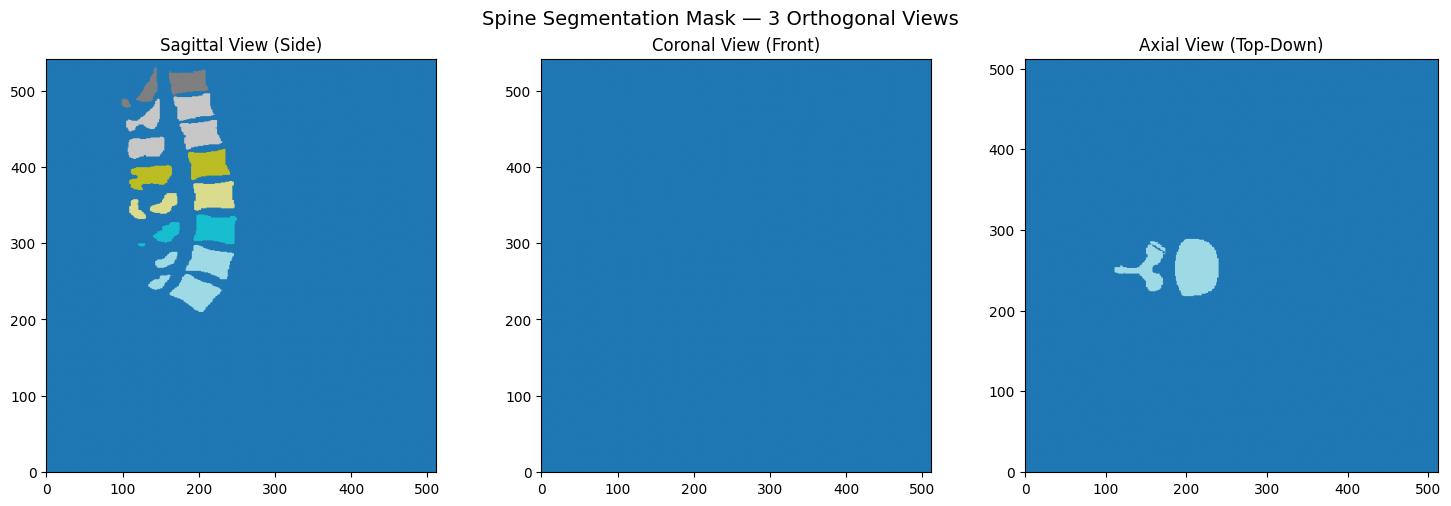

In [1]:
# Load NIfTI file
seg_nib = nib.load(seg_path)
seg_data = np.asanyarray(seg_nib.dataobj).astype(np.uint8)

# Extract physical spacing in millimeters
voxel_spacing = tuple(float(s) for s in seg_nib.header.get_zooms())

print(f"3D Array Shape:     {seg_data.shape}")
print(f"Voxel Spacing (mm): {voxel_spacing}")

labels_present = np.unique(seg_data)
print(f"Labels Present:     {labels_present}")

# Render orthogonal cross-sections
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
mid = [s // 2 for s in seg_data.shape]

axs[0].imshow(seg_data[mid[0], :, :].T, cmap="tab20", origin="lower")
axs[0].set_title("Sagittal View (Side)")
axs[0].set_xlabel("Y (mm)")
axs[0].set_ylabel("Z (mm)")

axs[1].imshow(seg_data[:, mid[1], :].T, cmap="tab20", origin="lower")
axs[1].set_title("Coronal View (Front)")
axs[1].set_xlabel("X (mm)")
axs[1].set_ylabel("Z (mm)")

axs[2].imshow(seg_data[:, :, mid[2]], cmap="tab20", origin="lower")
axs[2].set_title("Axial View (Top-Down)")
axs[2].set_xlabel("X (mm)")
axs[2].set_ylabel("Y (mm)")

plt.suptitle("Orthogonal Views of Spinal Segmentation Mask", fontsize=14)
plt.tight_layout()
plt.show()


## 4. Single-Bone Surface Reconstruction (Vertebra L3)

The core reconstruction procedure extracts an individual bone label using Marching Cubes, scales coordinates by voxel spacing, and post-processes the raw mesh:

1. **Binary Masking:** Isolate label 22 (L3).
2. **Isosurface Extraction:** Compute triangular facets at isovalue 0.5.
3. **Laplacian Smoothing:** Attenuate voxel stepping artifacts with 3 relaxation iterations (damping factor 0.5).
4. **Topological Healing:** Eliminate degenerate and unreferenced faces, and seal open holes to establish a watertight manifold.


--- Raw L3 Mesh ---
Number of Vertices (points): 44,716
Number of Faces (triangles): 89,432

--- Cleaned L3 Mesh ---
Is mesh watertight (closed solid)? True
Volume: 73955.5 mm³
Surface Area: 18198.2 mm²


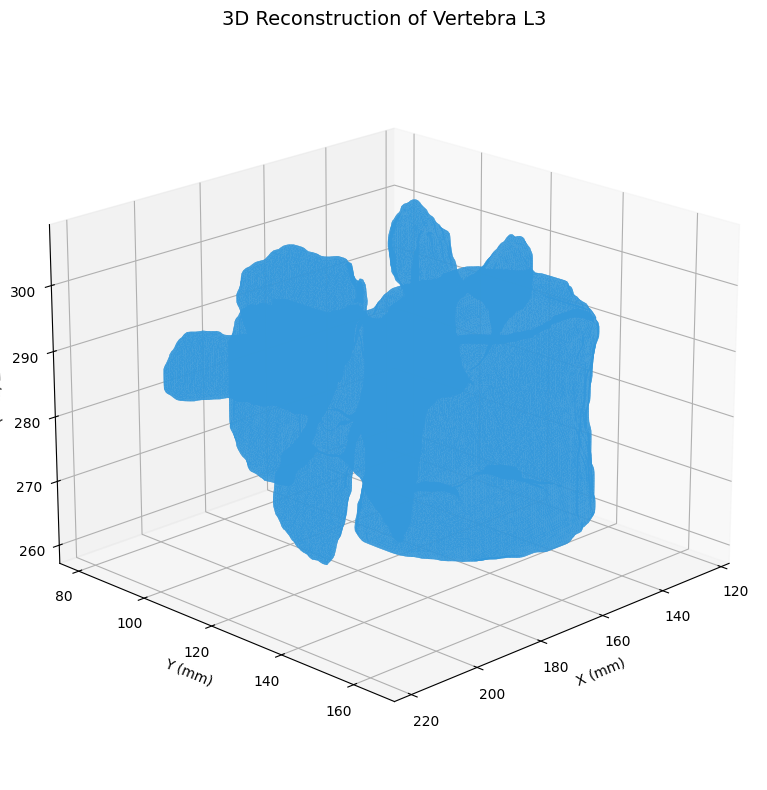

In [1]:
# Isolate vertebra L3 (Label 22)
TARGET_LABEL = 22
BONE_NAME = "L3"

binary_mask = (seg_data == TARGET_LABEL).astype(np.float32)

# Marching Cubes extraction scaled by physical spacing
verts, faces, normals, _ = measure.marching_cubes(
    binary_mask,
    level=0.5,
    spacing=voxel_spacing
)

print(f"Raw {BONE_NAME} Vertices: {len(verts):,}")
print(f"Raw {BONE_NAME} Faces:    {len(faces):,}")

# Build mesh and apply Laplacian smoothing
mesh_l3 = trimesh.Trimesh(vertices=verts, faces=faces, vertex_normals=normals)
mesh_l3 = trimesh.smoothing.filter_laplacian(mesh_l3, lamb=0.5, iterations=3)

# Topological validation and hole filling
mesh_l3.process(validate=True)
trimesh.repair.fill_holes(mesh_l3)

print(f"Watertight Manifold: {mesh_l3.is_watertight}")
print(f"Euler Number:        {mesh_l3.euler_number}")
print(f"Volume:              {abs(mesh_l3.volume):,.1f} mm³")
print(f"Surface Area:        {mesh_l3.area:,.1f} mm²")


## 5. 3D Visualization of Reconstructed L3 Mesh

The reconstructed L3 mesh is rendered in three-dimensional physical space. Key anatomical features visible include:
* **Vertebral Body:** Anterior weight-bearing cylinder.
* **Pedicles:** Bilateral anchors connecting body to the posterior elements.
* **Transverse and Spinous Processes:** Musculoskeletal attachment sites.
* **Vertebral Foramen:** Central spinal cord canal.


--- Raw L3 Mesh ---
Number of Vertices (points): 44,716
Number of Faces (triangles): 89,432

--- Cleaned L3 Mesh ---
Is mesh watertight (closed solid)? True
Volume: 73955.5 mm³
Surface Area: 18198.2 mm²


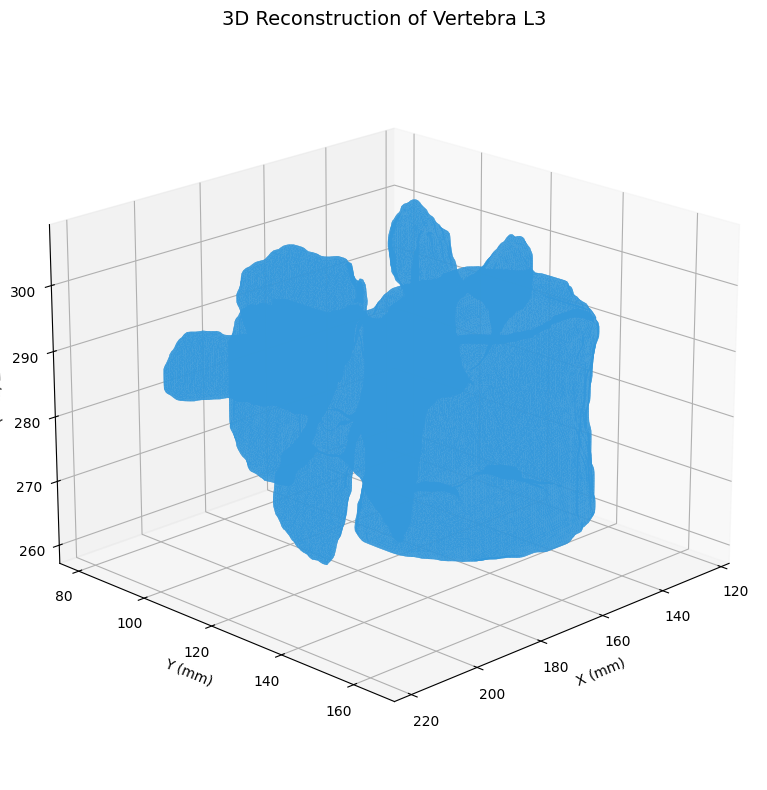

In [1]:
# Render 3D projection of vertebra L3
fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")

poly = Poly3DCollection(
    mesh_l3.vertices[mesh_l3.faces],
    alpha=0.92,
    facecolor="#3498db",
    edgecolor="none"
)
ax.add_collection3d(poly)

v = mesh_l3.vertices
ax.set_xlim(v[:, 0].min(), v[:, 0].max())
ax.set_ylim(v[:, 1].min(), v[:, 1].max())
ax.set_zlim(v[:, 2].min(), v[:, 2].max())

ax.set_title(f"3D Reconstruction of Vertebra {BONE_NAME} (Watertight STL)", fontsize=13)
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.view_init(elev=22, azim=48)

plt.tight_layout()
plt.show()


## 6. Batch Extraction, STL Export, and Morphometric Analysis

The extraction pipeline is executed across all vertebrae present in the dataset (T10 to L5). Each reconstructed bone is exported as an STL file, and quantitative geometric metrics are calculated:
* **Volume ($V$, $\text{mm}^3$):** Computed using Gauss's Divergence Theorem over closed triangular facets.
* **Surface Area ($A$, $\text{mm}^2$):** Sum of triangular face areas.
* **Compactness:** Dimensionless sphericity ratio indicating shape irregularity.


In [1]:
# Output directory for STL files
OUTPUT_DIR = "/kaggle/working/meshes"
os.makedirs(OUTPUT_DIR, exist_ok=True)

VERTEBRA_LABELS = {
    1:"C1", 2:"C2", 3:"C3", 4:"C4", 5:"C5", 6:"C6", 7:"C7",
    8:"T1", 9:"T2", 10:"T3", 11:"T4", 12:"T5", 13:"T6",
    14:"T7", 15:"T8", 16:"T9", 17:"T10", 18:"T11", 19:"T12",
    20:"L1", 21:"L2", 22:"L3", 23:"L4", 24:"L5", 25:"L6"
}

def extract_and_clean_mesh(seg_volume, label_id, spacing, output_path=None):
    binary_mask = (seg_volume == label_id).astype(np.float32)
    if binary_mask.sum() < 100:
        return None
        
    verts, faces, normals, _ = measure.marching_cubes(
        binary_mask, 
        level=0.5, 
        spacing=spacing
    )
    
    mesh = trimesh.Trimesh(vertices=verts, faces=faces, vertex_normals=normals)
    mesh = trimesh.smoothing.filter_laplacian(mesh, lamb=0.5, iterations=3)
    mesh.process(validate=True)
    trimesh.repair.fill_holes(mesh)
    
    if output_path:
        mesh.export(output_path)
        
    return mesh

meshes = {}
records = []

print(f"{'Vertebra':<10} | {'Vertices':<10} | {'Faces':<10} | {'Volume (mm³)':<14} | {'Surface (mm²)':<14} | {'Compactness':<12}")
print("-" * 80)

for label_id in sorted(np.unique(seg_data)):
    if label_id == 0 or label_id not in VERTEBRA_LABELS:
        continue
        
    bone_name = VERTEBRA_LABELS[label_id]
    stl_file = os.path.join(OUTPUT_DIR, f"vertebra_{bone_name}.stl")
    
    mesh = extract_and_clean_mesh(seg_data, label_id, voxel_spacing, output_path=stl_file)
    
    if mesh is not None:
        meshes[bone_name] = mesh
        vol = abs(mesh.volume)
        surf = mesh.area
        compactness = (36 * np.pi * (vol**2))**(1/3) / surf if surf > 0 else 0
        
        records.append({
            "vertebra": bone_name,
            "label_id": label_id,
            "vertices": len(mesh.vertices),
            "faces": len(mesh.faces),
            "volume_mm3": round(vol, 1),
            "surface_area_mm2": round(surf, 1),
            "compactness": round(compactness, 4),
            "is_watertight": mesh.is_watertight
        })
        
        print(f"{bone_name:<10} | {len(mesh.vertices):<10,d} | {len(mesh.faces):<10,d} | {vol:<14.1f} | {surf:<14.1f} | {compactness:<12.4f}")

df_geom = pd.DataFrame(records)
df_geom.to_csv("/kaggle/working/vertebra_geometry.csv", index=False)
print(f"\nBatch processing completed. STL files saved to {OUTPUT_DIR}")


Vertebra   | Vertices   | Faces      | Volume (mm³)   | Surface (mm²)  | Compactness 
--------------------------------------------------------------------------------
T10        | 30,394     | 60,788     | 45879.9        | 12131.5        | 0.5109      
T11        | 30,747     | 61,498     | 48673.4        | 12337.5        | 0.5225      
T12        | 34,135     | 68,274     | 57100.5        | 13624.3        | 0.5263      
L1         | 39,393     | 78,798     | 66201.5        | 16016.3        | 0.4941      
L2         | 41,835     | 83,674     | 70434.8        | 17159.7        | 0.4807      
L3         | 44,716     | 89,432     | 73955.5        | 18198.2        | 0.4682      
L4         | 42,878     | 85,756     | 72177.2        | 16927.1        | 0.4953      
L5         | 51,125     | 102,286    | 83091.1        | 19046.0        | 0.4835      

Saved vertebra_geometry.csv and all .stl files into /kaggle/working/meshes!


## 7. Multi-Class 3D Spinal Assembly

The reconstructed meshes are assembled into a unified 3D spatial coordinate system with region-specific anatomical coloring:
* **Thoracic (T10-T12):** Emerald Green
* **Lumbar (L1-L5):** Coral Red


In [ ]:
REGION_COLORS = {
    **{i: [0.18, 0.80, 0.44] for i in range(8, 20)},   # Thoracic: Green
    **{i: [0.91, 0.30, 0.24] for i in range(20, 26)},  # Lumbar:   Red
}

fig = plt.figure(figsize=(9, 13))
ax = fig.add_subplot(111, projection="3d")

name_to_label = {v: k for k, v in VERTEBRA_LABELS.items()}

for name, mesh in meshes.items():
    label_id = name_to_label.get(name, 0)
    color = REGION_COLORS.get(label_id, [0.7, 0.7, 0.7])
    
    poly = Poly3DCollection(
        mesh.vertices[mesh.faces],
        alpha=0.88,
        facecolor=color,
        edgecolor="none"
    )
    ax.add_collection3d(poly)

all_verts = np.concatenate([m.vertices for m in meshes.values()])
ax.set_xlim(all_verts[:, 0].min(), all_verts[:, 0].max())
ax.set_ylim(all_verts[:, 1].min(), all_verts[:, 1].max())
ax.set_zlim(all_verts[:, 2].min(), all_verts[:, 2].max())

ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.set_title("Full Thoracolumbar Spine 3D Reconstruction", fontsize=14)
ax.view_init(elev=18, azim=42)

plt.tight_layout()
plt.savefig("/kaggle/working/spine_3d_reconstruction.png", dpi=200, bbox_inches="tight")
plt.show()


## 8. Clinical Validation in 3D Slicer

The exported STL files were imported directly into 3D Slicer (v5.12.4) to confirm geometric fidelity, surface continuity, and spatial alignment in an established medical imaging environment. 

The resulting surface models verify:
* Continuous surface manifolds across all extracted vertebrae.
* Accurate spatial relationship along the thoracic and lumbar curvature.
* Direct compatibility with surgical navigation, implant template positioning, and additive manufacturing workflows.
